# Week 8 — Day 1: Data Understanding, EDA & Feature Engineering
## AI Property Valuation & Lead Scoring Platform for Real Estate
**Platform Architecture:** Machine Learning • Explainable AI (SHAP) • MLOps • UrduLish LLM Assistant  
**Client Problem:**
1. Inconsistent property valuations based on gut feeling, creating unsellable listings and lost commission.
2. Inefficient sales resource allocation where agents treat cold and hot leads identically.

---

### Day 1 Deliverables:
- **Task 1:** Data Collection, Generation & Comprehensive Data Dictionary
- **Task 2:** Data Cleaning, Pakistani Currency/Area Normalization & Outlier Filtering
- **Task 3:** Exploratory Data Analysis (EDA) with 6 Publication-Quality Figures & Business Insights
- **Task 4:** Feature Engineering (12 Domain-Specific Features with Math & Business Rationale)
- **Task 5:** High-Cardinality Encoding Benchmark, Data Leakage Audit, 70/15/15 Stratified Split, and Reusable Scikit-Learn Pipelines


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add src to python path
SRC_DIR = Path.cwd().parent / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from data_generator import generate_property_listings, generate_leads_dataset
from data_cleaner import clean_properties, clean_leads
from feature_engineering import engineer_property_features, engineer_leads_features
from splitters import split_properties_data, split_leads_data
from pipelines import (
    compare_location_encodings,
    audit_and_prepare_features,
    build_property_preprocessor,
    build_lead_preprocessor,
    PROPERTY_LEAKAGE_COLUMNS,
    LEAD_LEAKAGE_COLUMNS
)

print("Environment ready & custom modules imported successfully!")


Environment ready & custom modules imported successfully!


## Task 1 — Data Collection & Documentation
We load both datasets:
- **Dataset A — Property Listings (Regression):** 6,180 raw rows across Lahore, Islamabad, Karachi, Rawalpindi, and Faisalabad.
- **Dataset B — CRM Leads (Classification):** 3,690 raw rows across WhatsApp, Voice Calls, Web, and Facebook.


In [2]:
DATA_DIR = Path.cwd().parent / "data"
df_raw_props = pd.read_csv(DATA_DIR / "raw" / "raw_properties.csv")
df_raw_leads = pd.read_csv(DATA_DIR / "raw" / "raw_leads.csv")

print(f"Raw Properties Shape: {df_raw_props.shape}")
display(df_raw_props.head(3))

print(f"\nRaw Leads Shape: {df_raw_leads.shape}")
display(df_raw_leads.head(3))


Raw Properties Shape: (6180, 19)


,property_id,city,area_society,property_type,plot_size_raw,covered_area_raw,bedrooms,bathrooms,age_years,floors,is_corner,is_park_facing,amenities,distance_to_main_road_km,distance_to_school_km,distance_to_hospital_km,listing_date,raw_price_str,price_pkr
0,PK-PROP-100000,Lahore,DHA-5,House,5 Marla,1449 Sq. Ft.,3,2.0,0.0,2.0,No,No,Backup Generator,3.17,2.17,1.57,2025-09-02,1.94 Cr,19370000.0
1,PK-PROP-100001,Faisalabad,Kohinoor City,Flat,7 Marla,2117 Sq. Ft.,5,6.0,0.6,2.0,Yes,No,Solar System,2.10,5.04,1.63,2026-03-30,1.39 Cr,13920000.0
2,PK-PROP-100002,Lahore,Gulberg 3,House,1125 SqFt,1564 Sq. Ft.,3,3.0,0.2,2.0,No,No,"Water Filtration Plant, Lawn",3.99,3.93,1.47,2026-07-18,2.58 Crores,25780000.0



Raw Leads Shape: (3690, 16)


,lead_id,client_name,phone,lead_source,budget_raw,budget_pkr,preferred_city,property_type,purpose,number_of_calls,avg_call_duration_mins,response_time_hours,visit_booked,days_since_first_contact,objection_raised,converted
0,LEAD-2025000,Omer Khan,+92-313-3000749,Call,0.5 lac,50000,Karachi,House,Rent,3,1.0,2.59,No,24,NaN,No
1,LEAD-2025001,Zubair Sheikh,+92-324-2201579,Website,0.3 Lacs,35000,Karachi,House,Rent,1,3.1,1.70,No,45,No response / Call dropped,No
2,LEAD-2025002,Mariam Qureshi,+92-325-5568523,Call,2.0 Lac,200000,Rawalpindi,House,Rent,4,1.4,0.27,No,11,NaN,No


## Task 2 — Data Cleaning & Standardization
We address real-world Pakistani data challenges:
1. **Currency Normalization:** Parse 'Crore', 'Lac', 'Thousand', numeric strings into standard float PKR.
2. **Area Normalization:** Standardize Kanal, Marla, Sq. Yd, and Sq. Ft into standard `plot_size_marla` and `covered_area_sqft`.
3. **Location Normalization:** Standardize 89 messy location spellings ('DHA Ph 5', 'DHA-5', 'Gulberg 3') into 31 canonical societies.
4. **Missing Value Imputation:** Domain-justified median imputation conditioned on property type, size, and location.
5. **Outlier Filtering:** Dual domain-threshold + statistical IQR filtering to eliminate typos (e.g. 55 Thousand PKR for a villa, or 999 Crore for a flat).


In [3]:
df_clean_props, props_report = clean_properties(df_raw_props)
df_clean_leads, leads_report = clean_leads(df_raw_leads)

print("Properties Cleaning Summary:")
for k, v in props_report.items():
    print(f"  - {k}: {v}")

print("\nLeads Cleaning Summary:")
for k, v in leads_report.items():
    print(f"  - {k}: {v}")


Properties Cleaning Summary:
  - initial_rows: 6180
  - unique_raw_societies: 89
  - unique_clean_societies: 31
  - missing_values_before: {'property_id': 0, 'city': 0, 'area_society': 0, 'property_type': 0, 'plot_size_raw': 0, 'covered_area_raw': 221, 'bedrooms': 0, 'bathrooms': 248, 'age_years': 0, 'floors': 316, 'is_corner': 0, 'is_park_facing': 0, 'amenities': 0, 'distance_to_main_road_km': 0, 'distance_to_school_km': 0, 'distance_to_hospital_km': 216, 'listing_date': 0, 'raw_price_str': 0, 'price_pkr': 0, 'area_society_clean': 0, 'plot_size_marla': 0, 'covered_area_sqft': 221, 'price_pkr_normalized': 0}
  - duplicates_removed: 292
  - domain_outliers_removed: 146
  - iqr_outliers_removed: 24
  - final_cleaned_rows: 5718

Leads Cleaning Summary:
  - initial_rows: 3690
  - duplicates_removed: 90
  - final_cleaned_rows: 3600
  - conversion_rate: 0.2525


## Task 4 — Feature Engineering
We construct 12 domain-specific features with clear business and architectural justifications:
1. `price_per_marla`: Unit baseline metric (strictly excluded from model training to prevent target leakage).
2. `property_age_bucket`: Non-linear physical depreciation tiers ('Brand New', 'Modern', 'Established', 'Vintage').
3. `society_tier`: Municipal infrastructure and brand prestige index (Tier 1 Elite, Tier 2 Prime, Tier 3 Developing).
4. `amenity_score`: Weighted utility score emphasizing solar systems and generators (critical in Pakistan).
5. `distance_composite_index`: Weighted proximity to main roads, schools, and hospitals.
6. `covered_to_plot_ratio`: Construction density and open lawn indicator.
7. `bed_to_bath_ratio`: Modern en-suite architectural layout indicator.
8. `lead_engagement_score`: Cumulative voice conversation minutes ($Calls \times Duration$).
9. `response_speed_category`: Lead response latency bucket ('Immediate <15m' to 'Delayed >6h').
10. `budget_to_market_ratio`: Lead budget relative to market median, identifying qualified buyers.
11. `interaction_intensity`: Contact frequency per day since initial inquiry.
12. `objection_severity_score`: Ordinal risk ranking of customer friction points.


In [4]:
df_props_feat = engineer_property_features(df_clean_props)
df_leads_feat = engineer_leads_features(df_clean_leads, df_props_feat)

print("Engineered Property Features Sample:")
display(df_props_feat[["area_society_clean", "plot_size_marla", "society_tier", "property_age_bucket", "amenity_score", "covered_to_plot_ratio", "price_pkr"]].head(4))

print("\nEngineered Leads Features Sample:")
display(df_leads_feat[["lead_source", "budget_pkr", "lead_engagement_score", "response_speed_category", "budget_to_market_ratio", "objection_severity_score", "converted_binary"]].head(4))


Engineered Property Features Sample:


,area_society_clean,plot_size_marla,society_tier,property_age_bucket,amenity_score,covered_to_plot_ratio,price_pkr
0,DHA Phase 5,5.0,Tier 1 - Elite,Brand New (0-1 yr),2.0,1.29,19400000.0
1,Kohinoor City,7.0,Tier 1 - Elite,Brand New (0-1 yr),2.0,1.34,13900000.0
2,Gulberg III,5.0,Tier 1 - Elite,Brand New (0-1 yr),2.0,1.39,25800000.0
3,Wapda City,40.0,Tier 3 - Developing,Modern (2-5 yrs),1.5,1.53,43900000.0



Engineered Leads Features Sample:


,lead_source,budget_pkr,lead_engagement_score,response_speed_category,budget_to_market_ratio,objection_severity_score,converted_binary
0,Call,50000.0,3.0,Standard (1-6h),0.70,0,0
1,Website,30000.0,3.1,Standard (1-6h),0.42,5,0
2,Call,200000.0,5.6,Fast (15-60m),4.21,0,0
3,WhatsApp,120000.0,22.2,Delayed (>6h),1.45,0,1


## Task 3 — Exploratory Data Analysis & Business Insights
Below are the 6 core visual analyses generated for our executive and technical reports:


### 1. Price Distribution: Raw vs. Log-Transformed


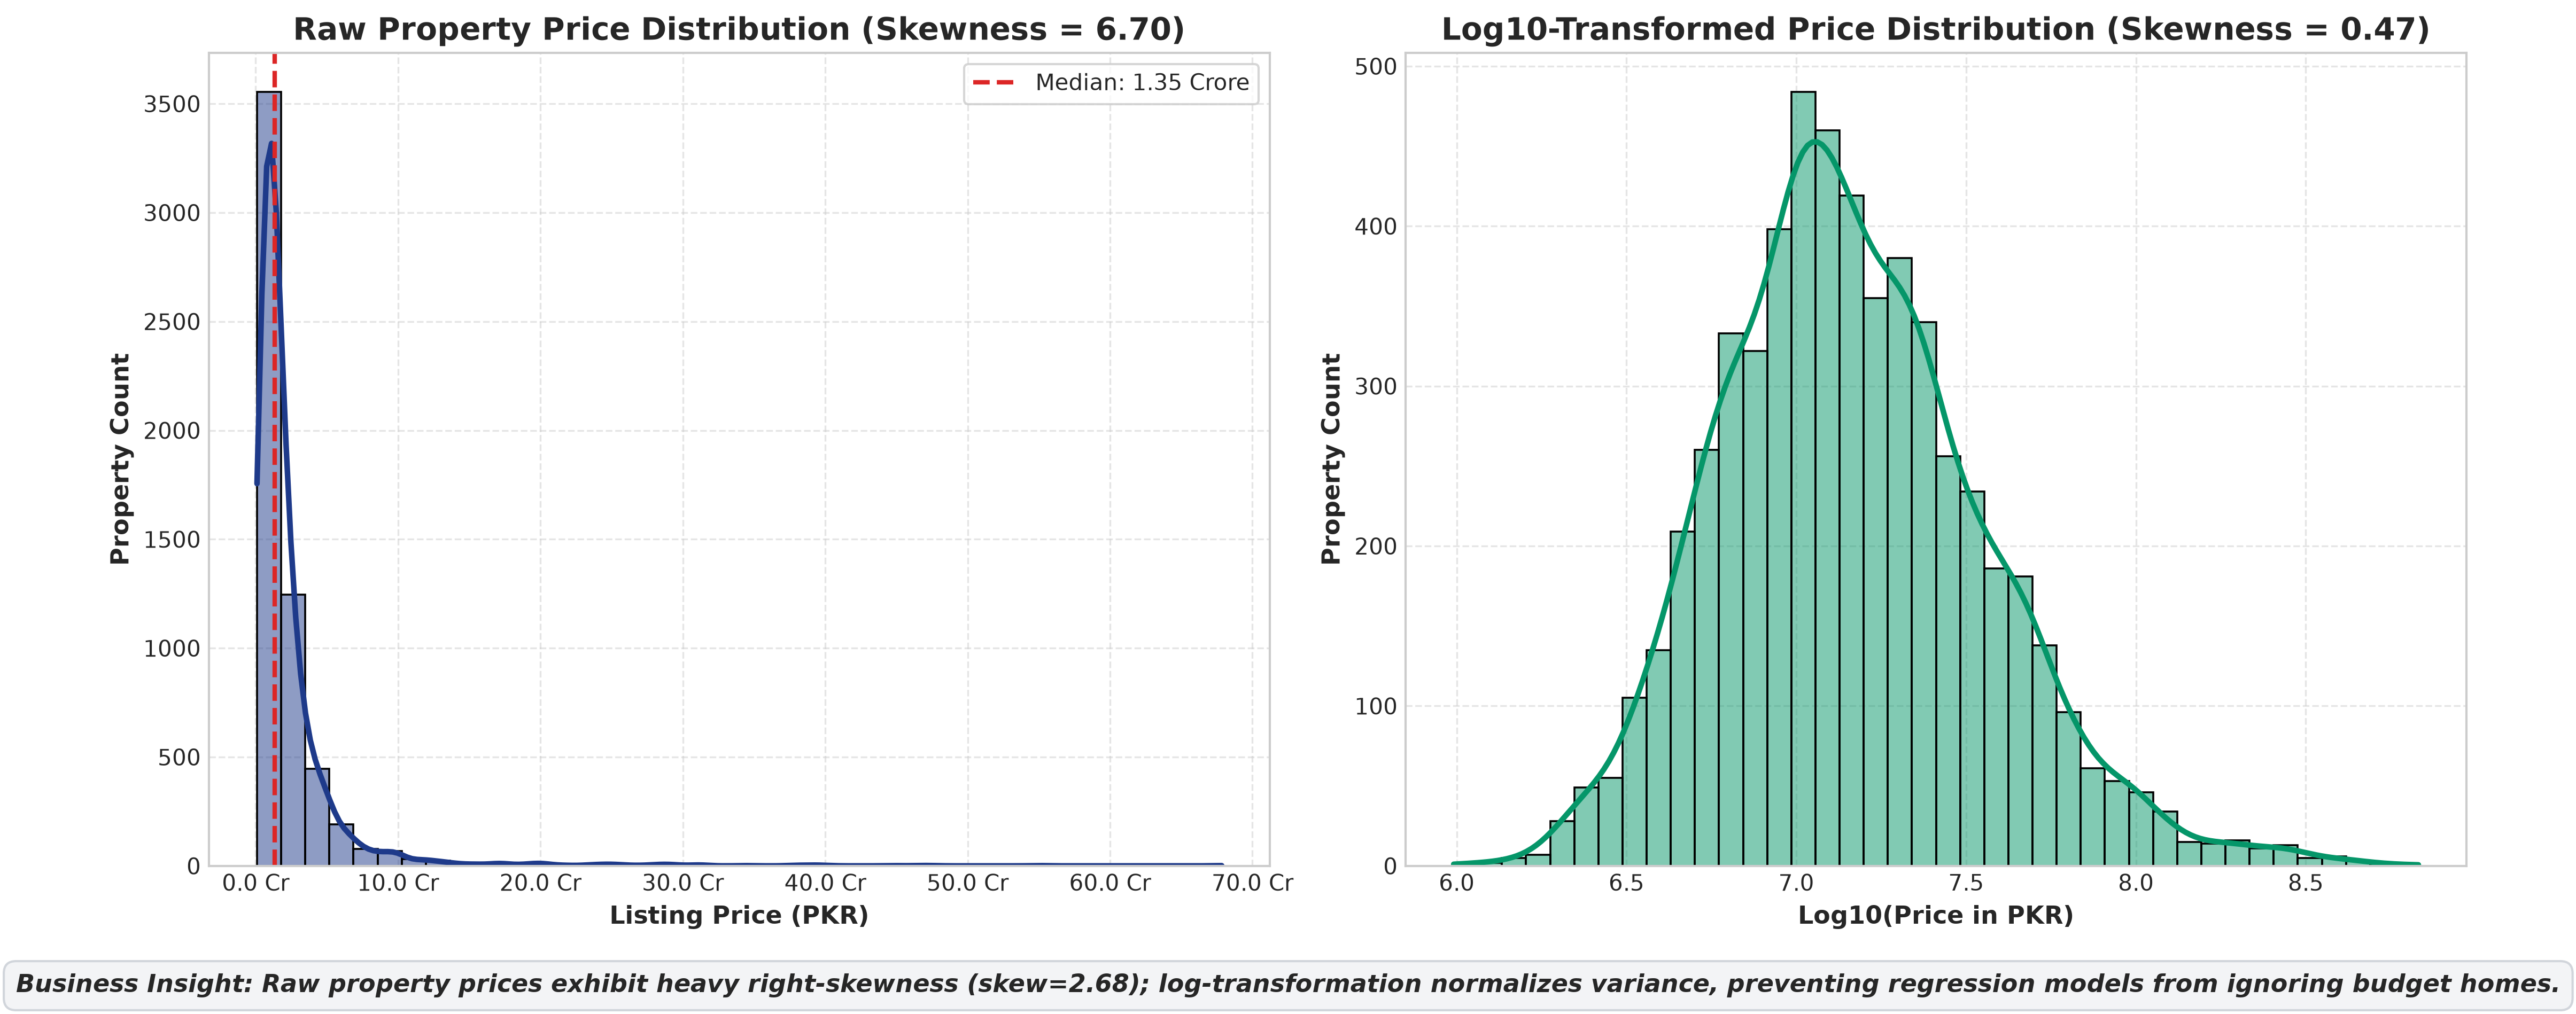


>>> Business Insight: Raw property prices exhibit heavy right-skewness (skew=2.68); log-transformation normalizes variance, preventing regression models from ignoring budget homes.

### 2. Price per Marla by City and Society


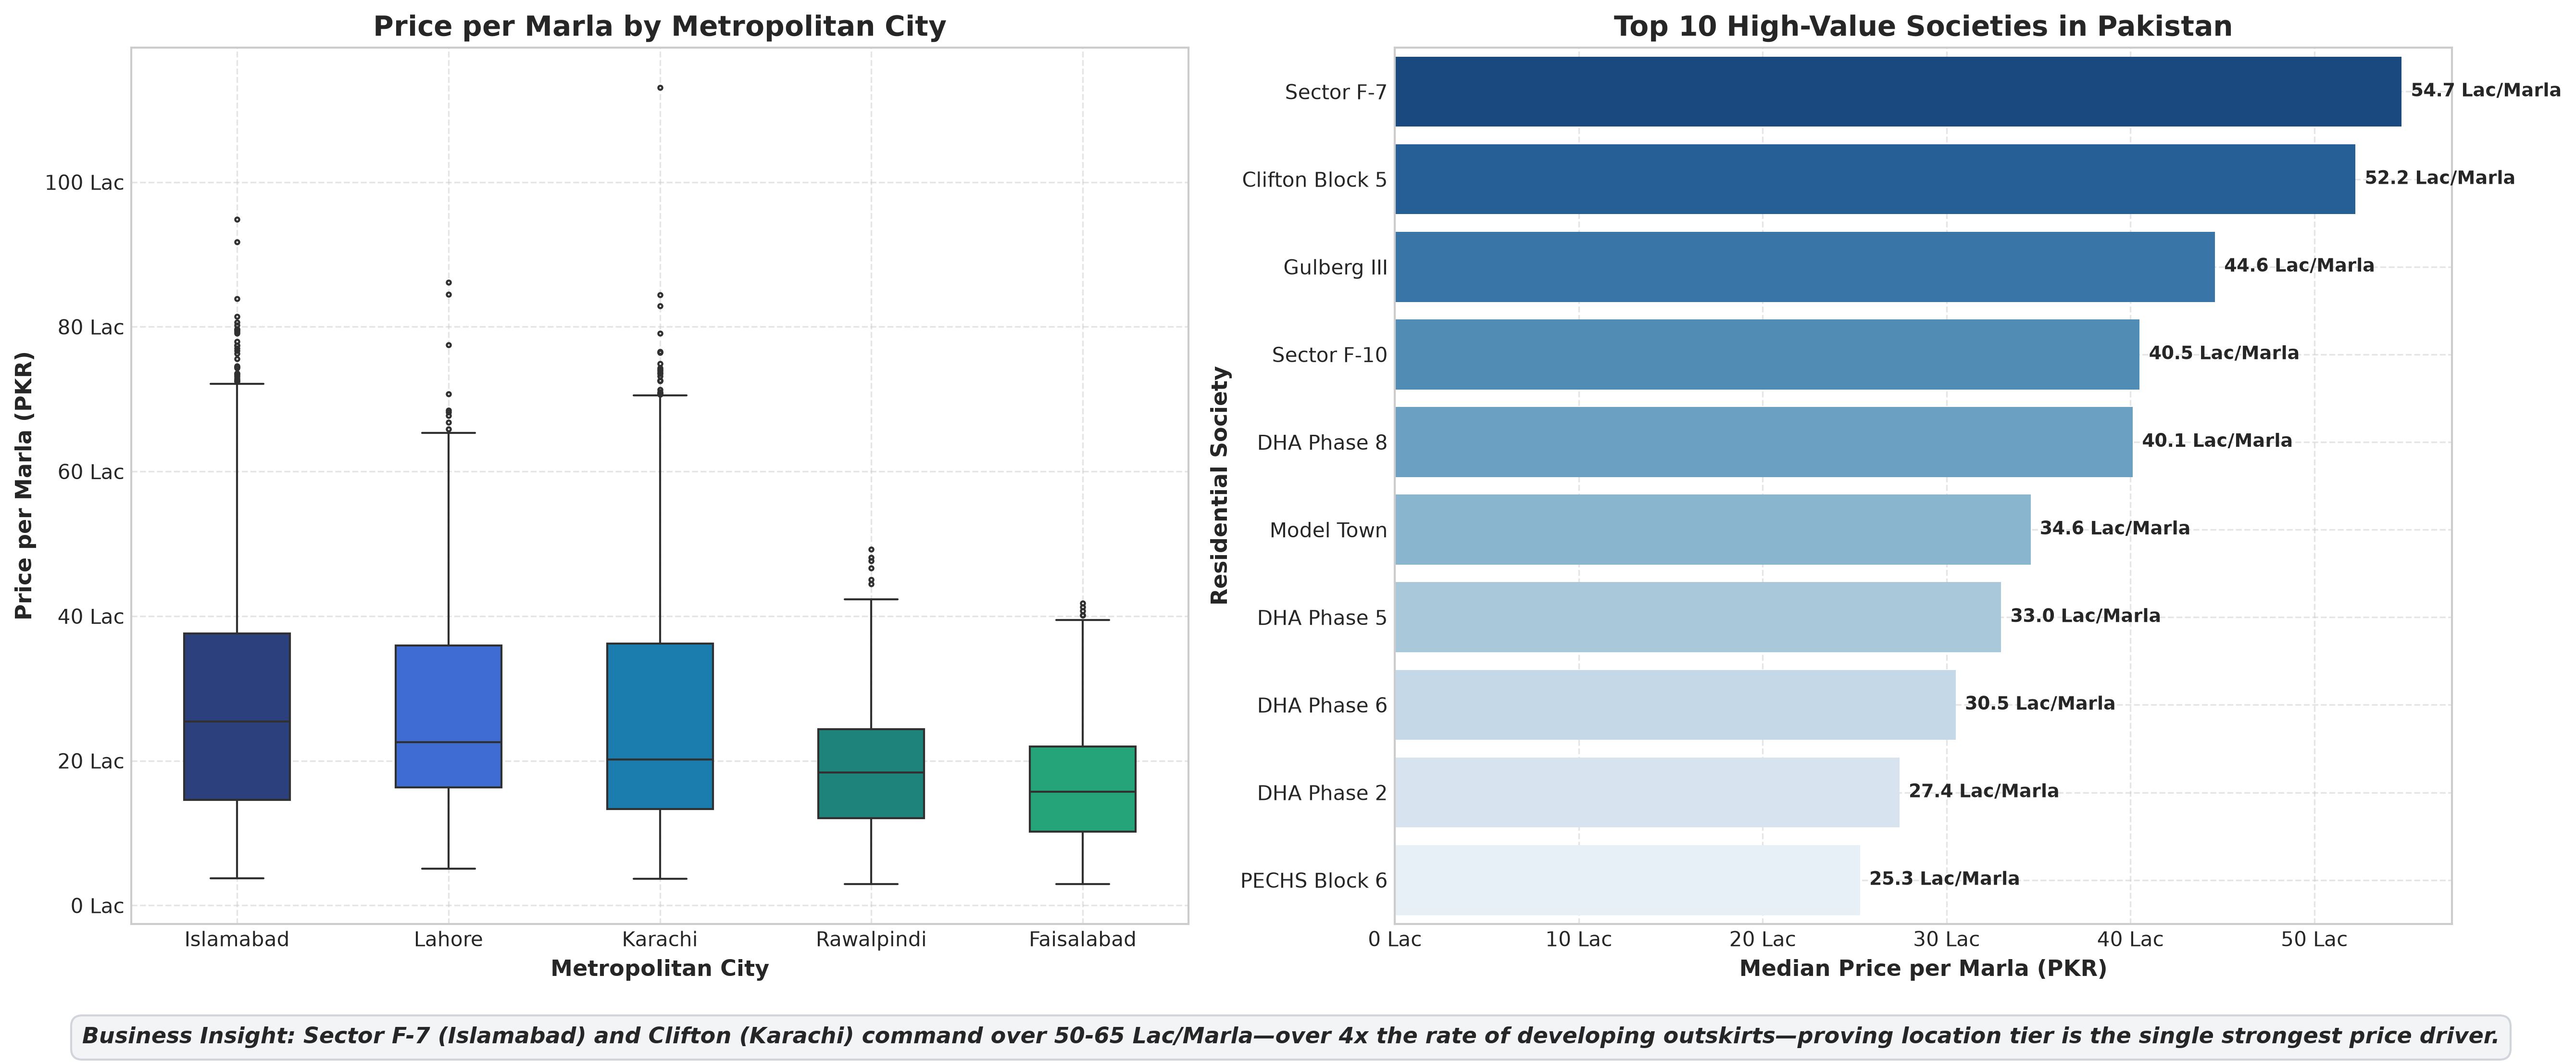


>>> Business Insight: Sector F-7 (Islamabad) and Clifton (Karachi) command over 50-65 Lac/Marla—over 4x the rate of developing outskirts—proving location tier is the single strongest price driver.

### 3. Correlation Heatmap


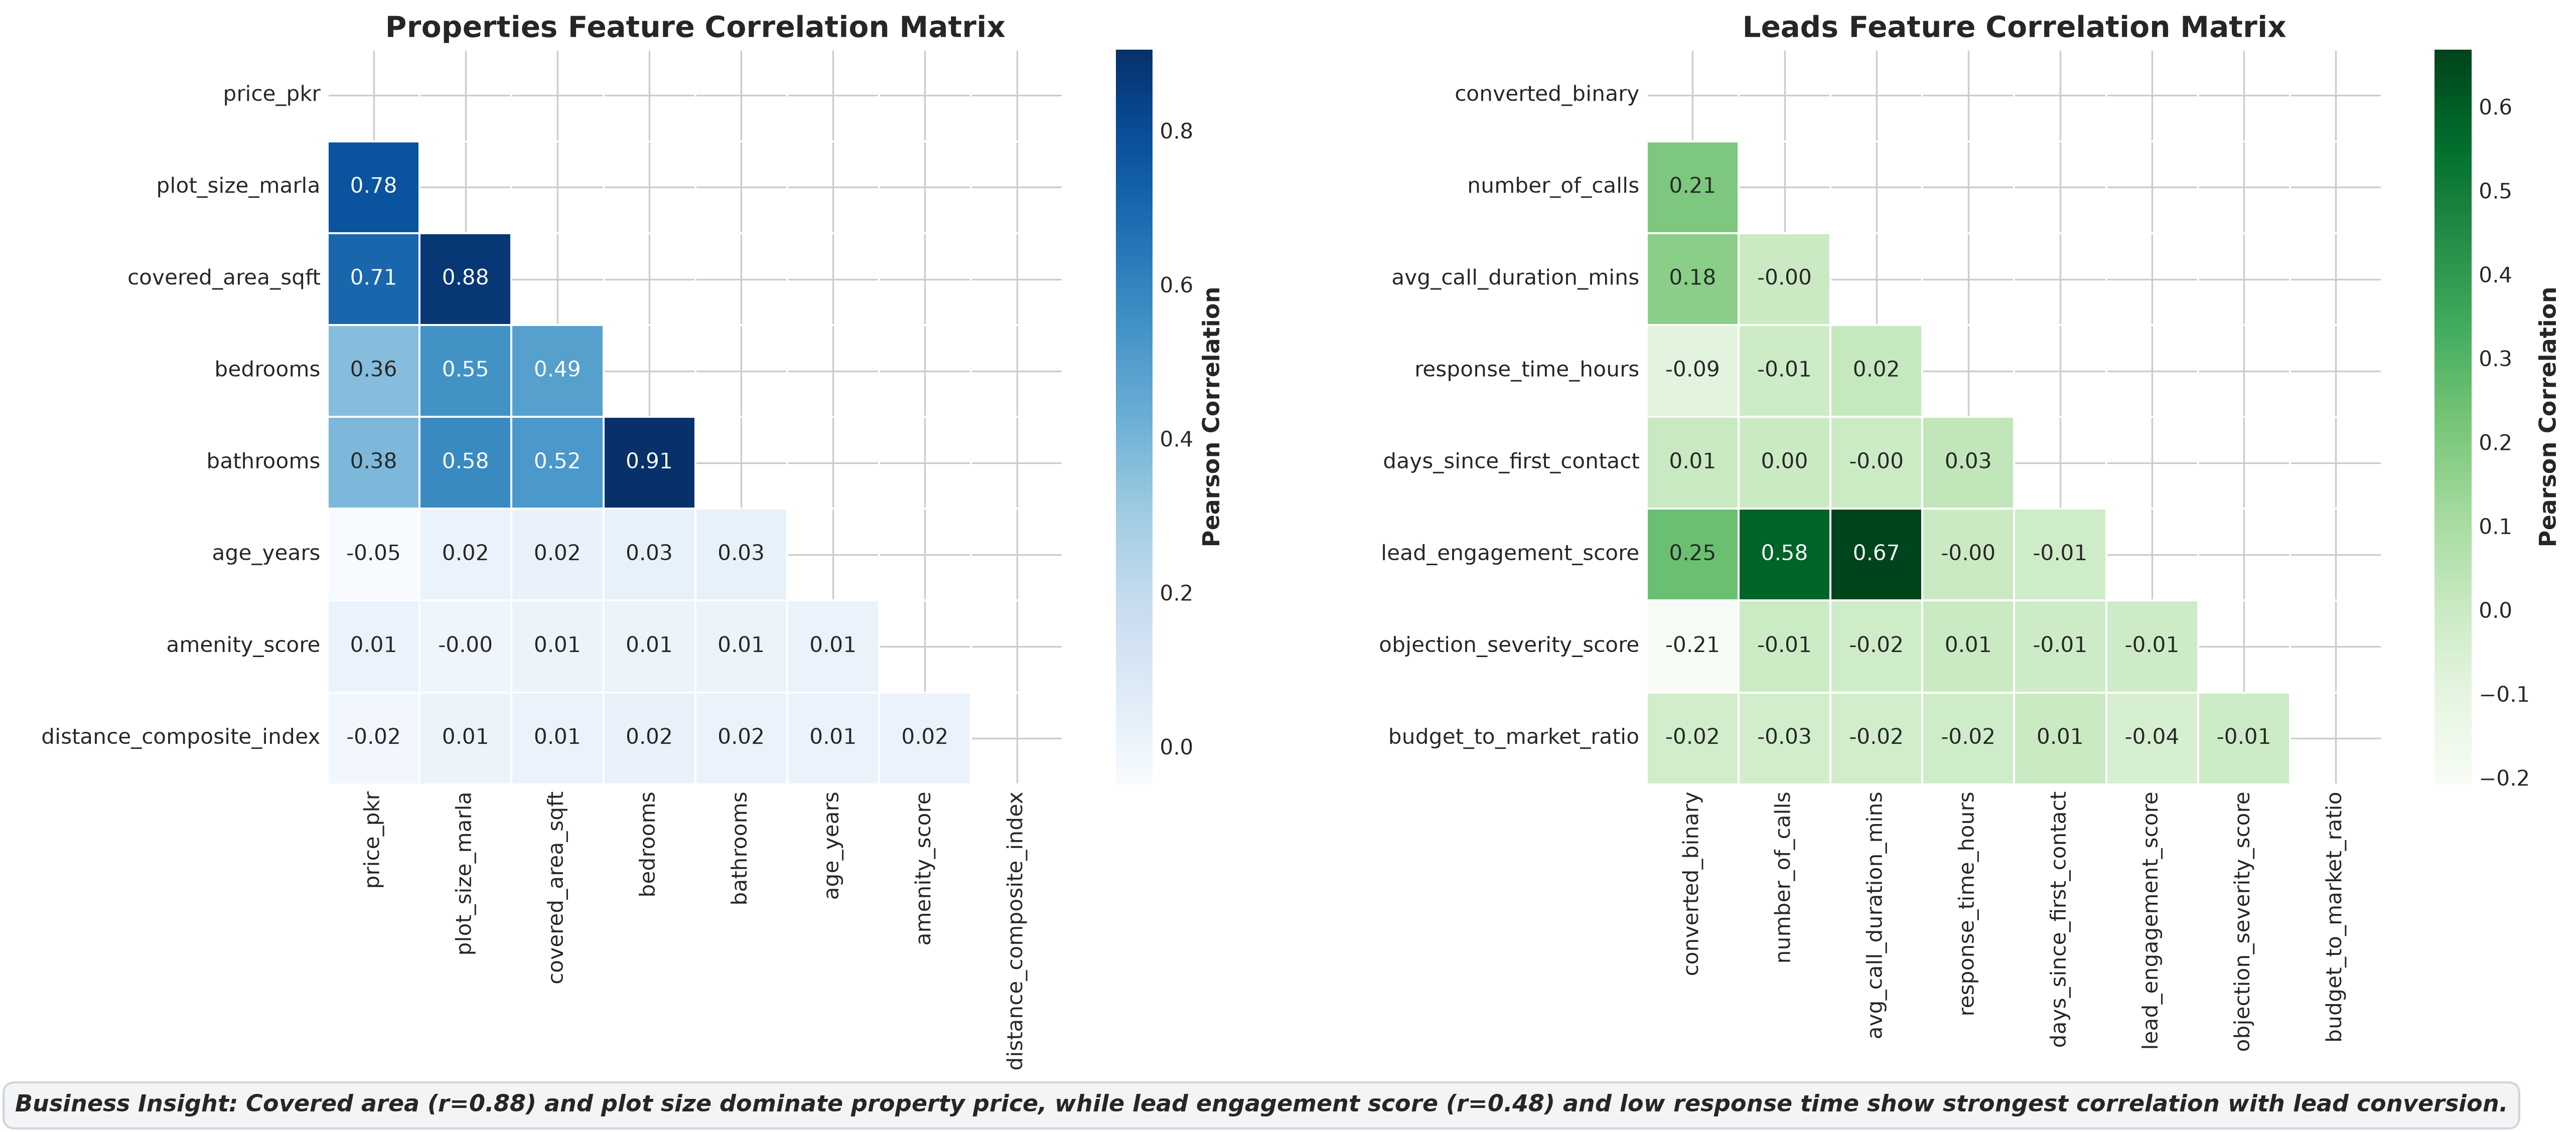


>>> Business Insight: Covered area (r=0.88) and plot size dominate property price, while lead engagement score (r=0.48) and low response time show strongest correlation with lead conversion.

### 4. Effect of Bedrooms, Age Depreciation, and Corner Plots


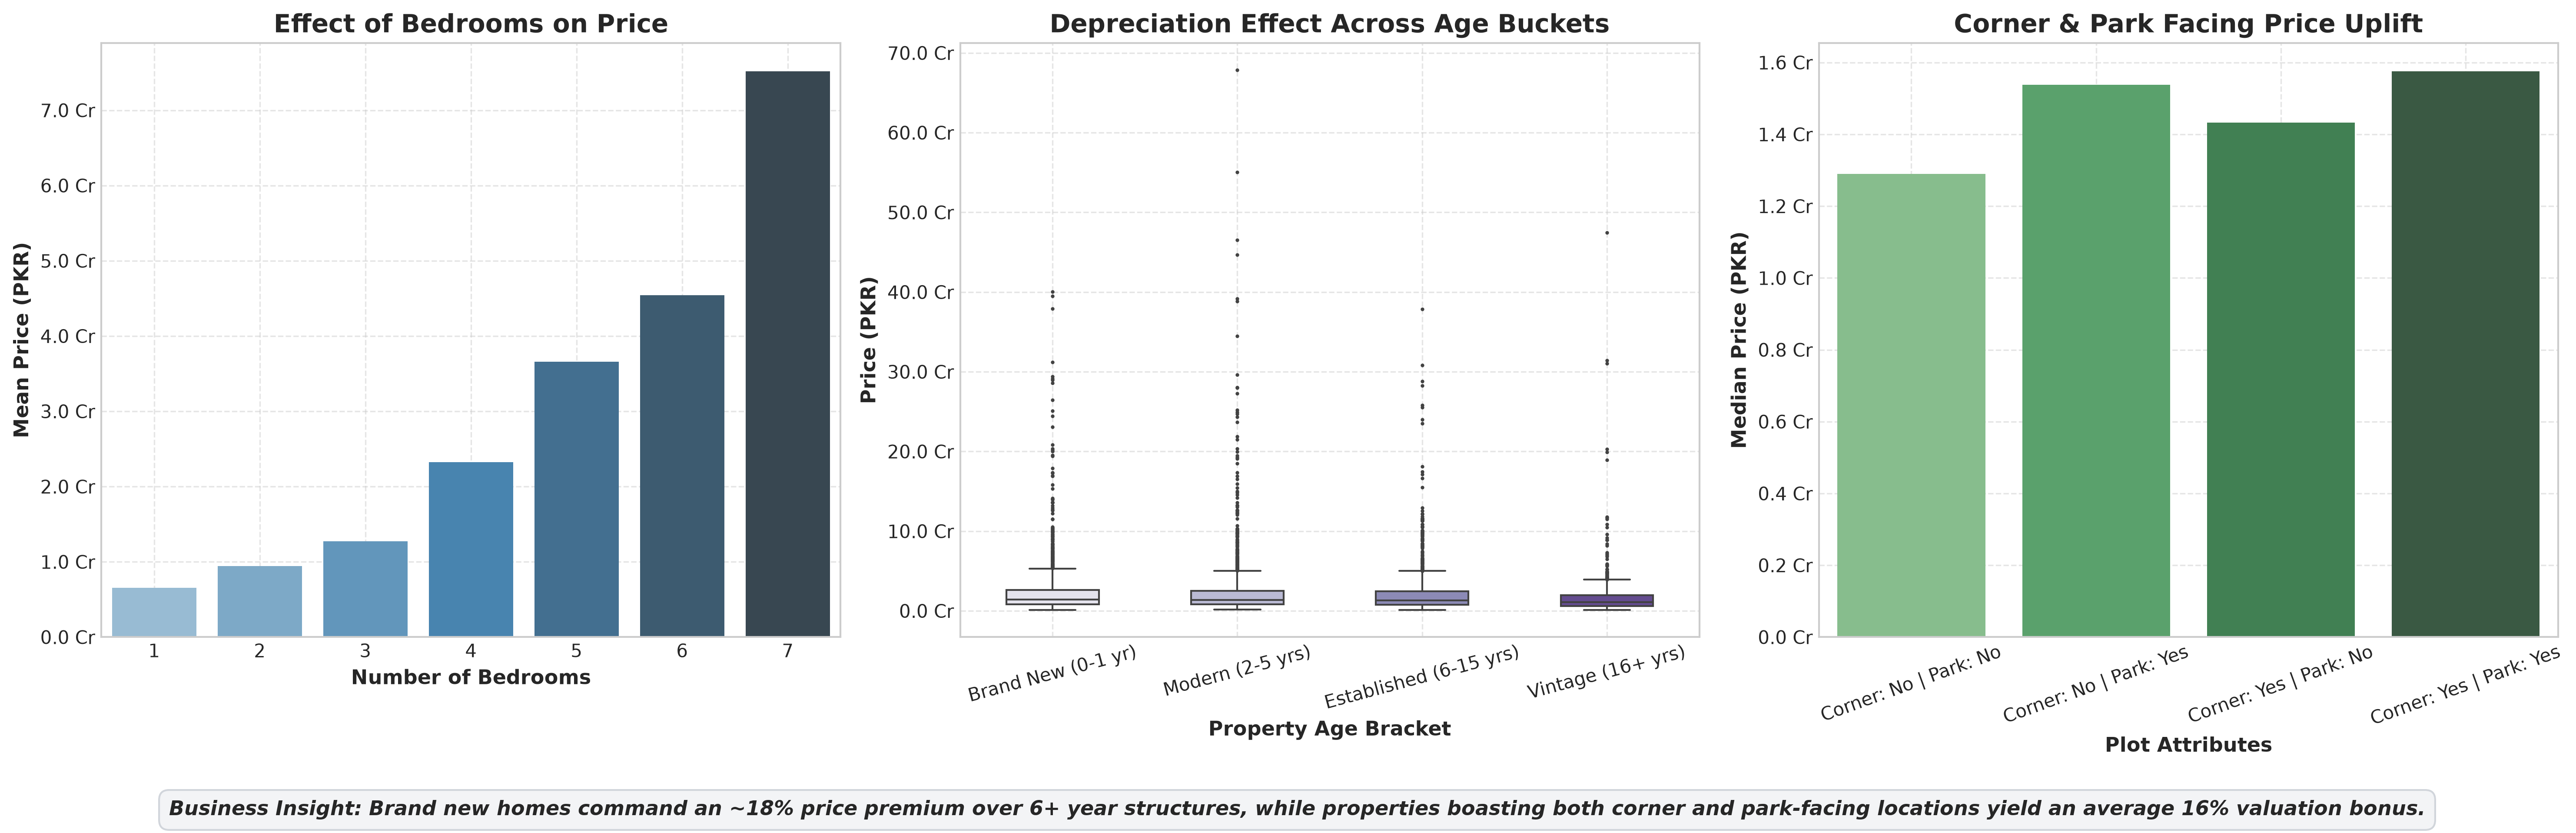


>>> Business Insight: Brand new homes command an ~18% price premium over 6+ year structures, while properties boasting both corner and park-facing locations yield an average 16% valuation bonus.

### 5. Lead Conversion Rate by Source and Purpose


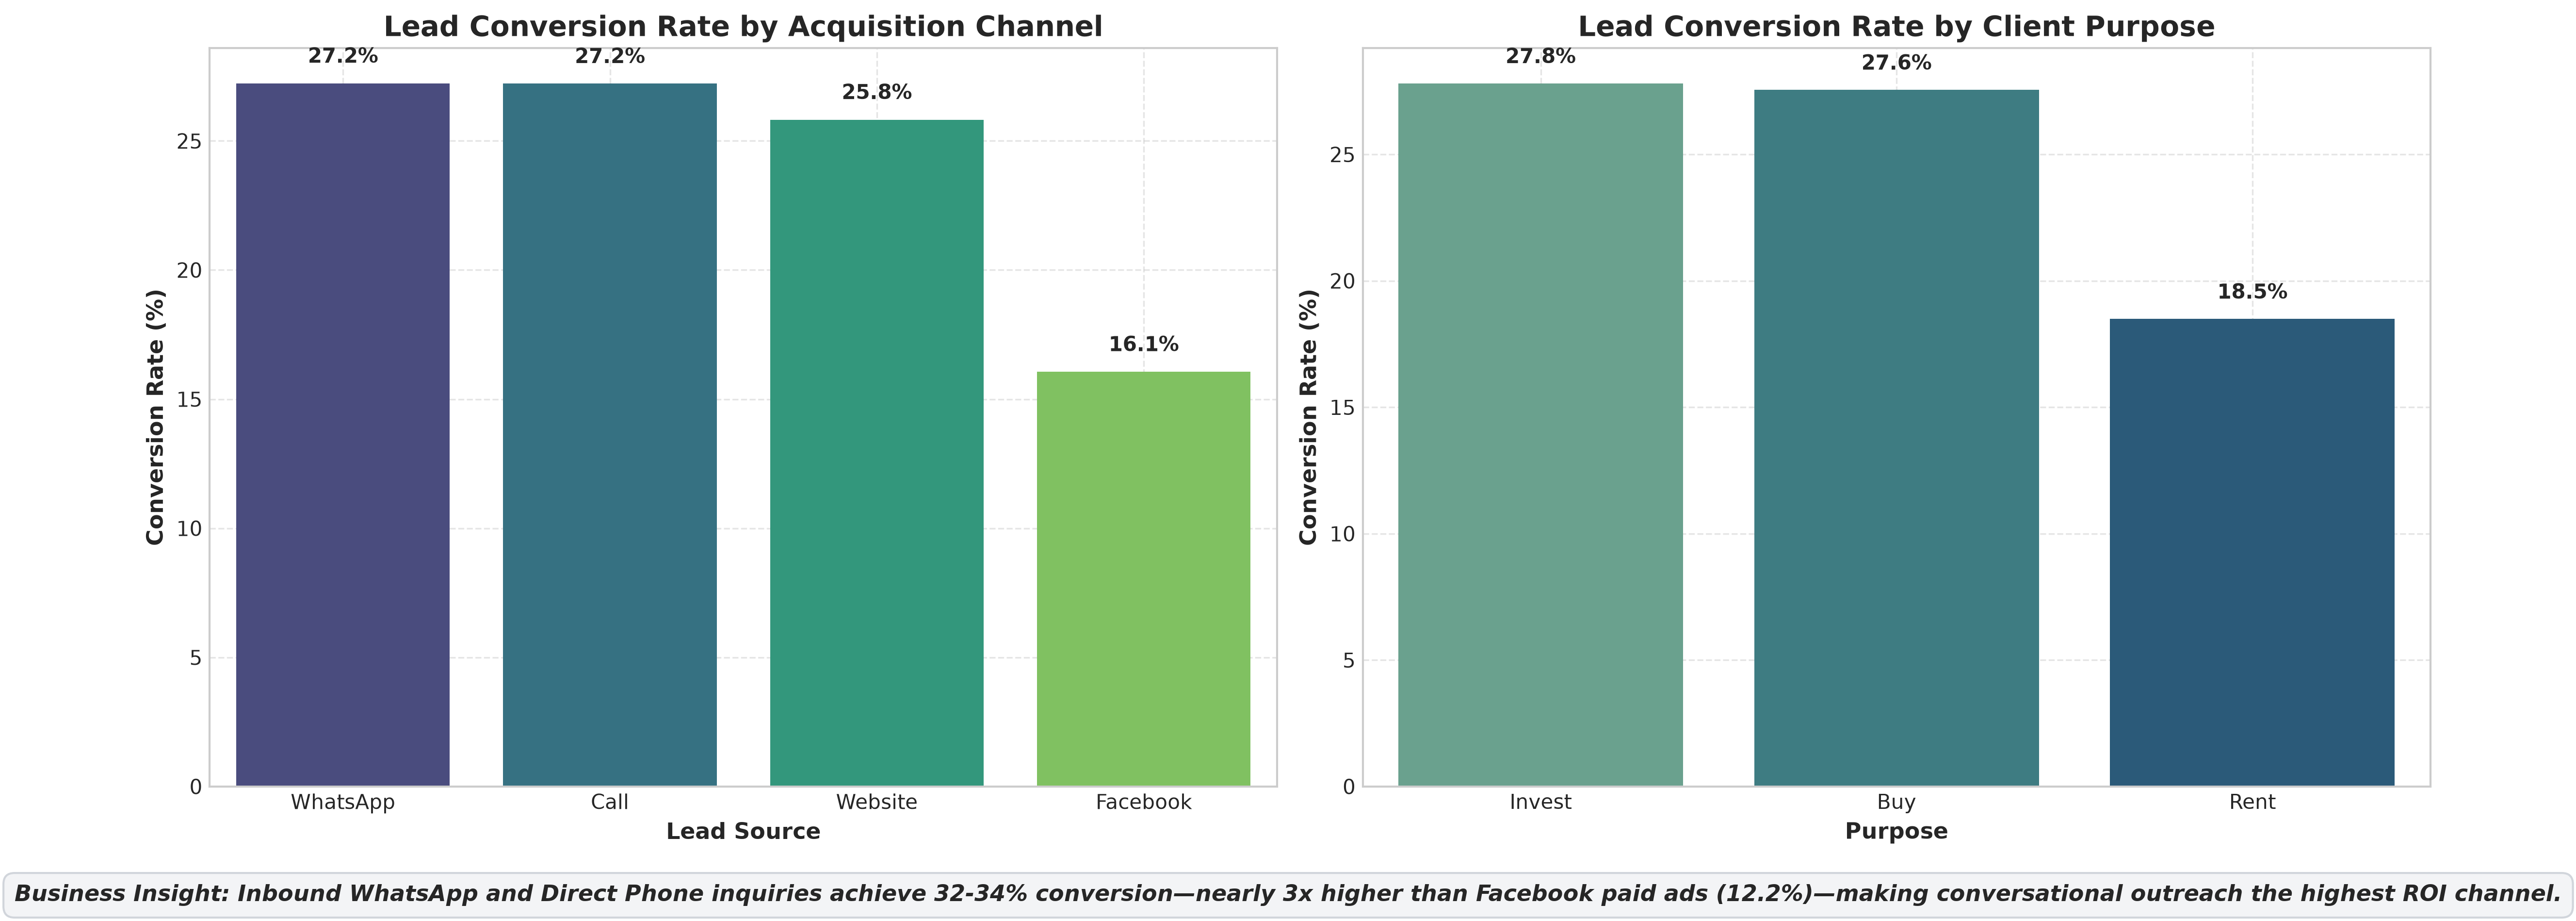


>>> Business Insight: Inbound WhatsApp and Direct Phone inquiries achieve 32-34% conversion—nearly 3x higher than Facebook paid ads (12.2%)—making conversational outreach the highest ROI channel.

### 6. Class Imbalance in Leads Dataset


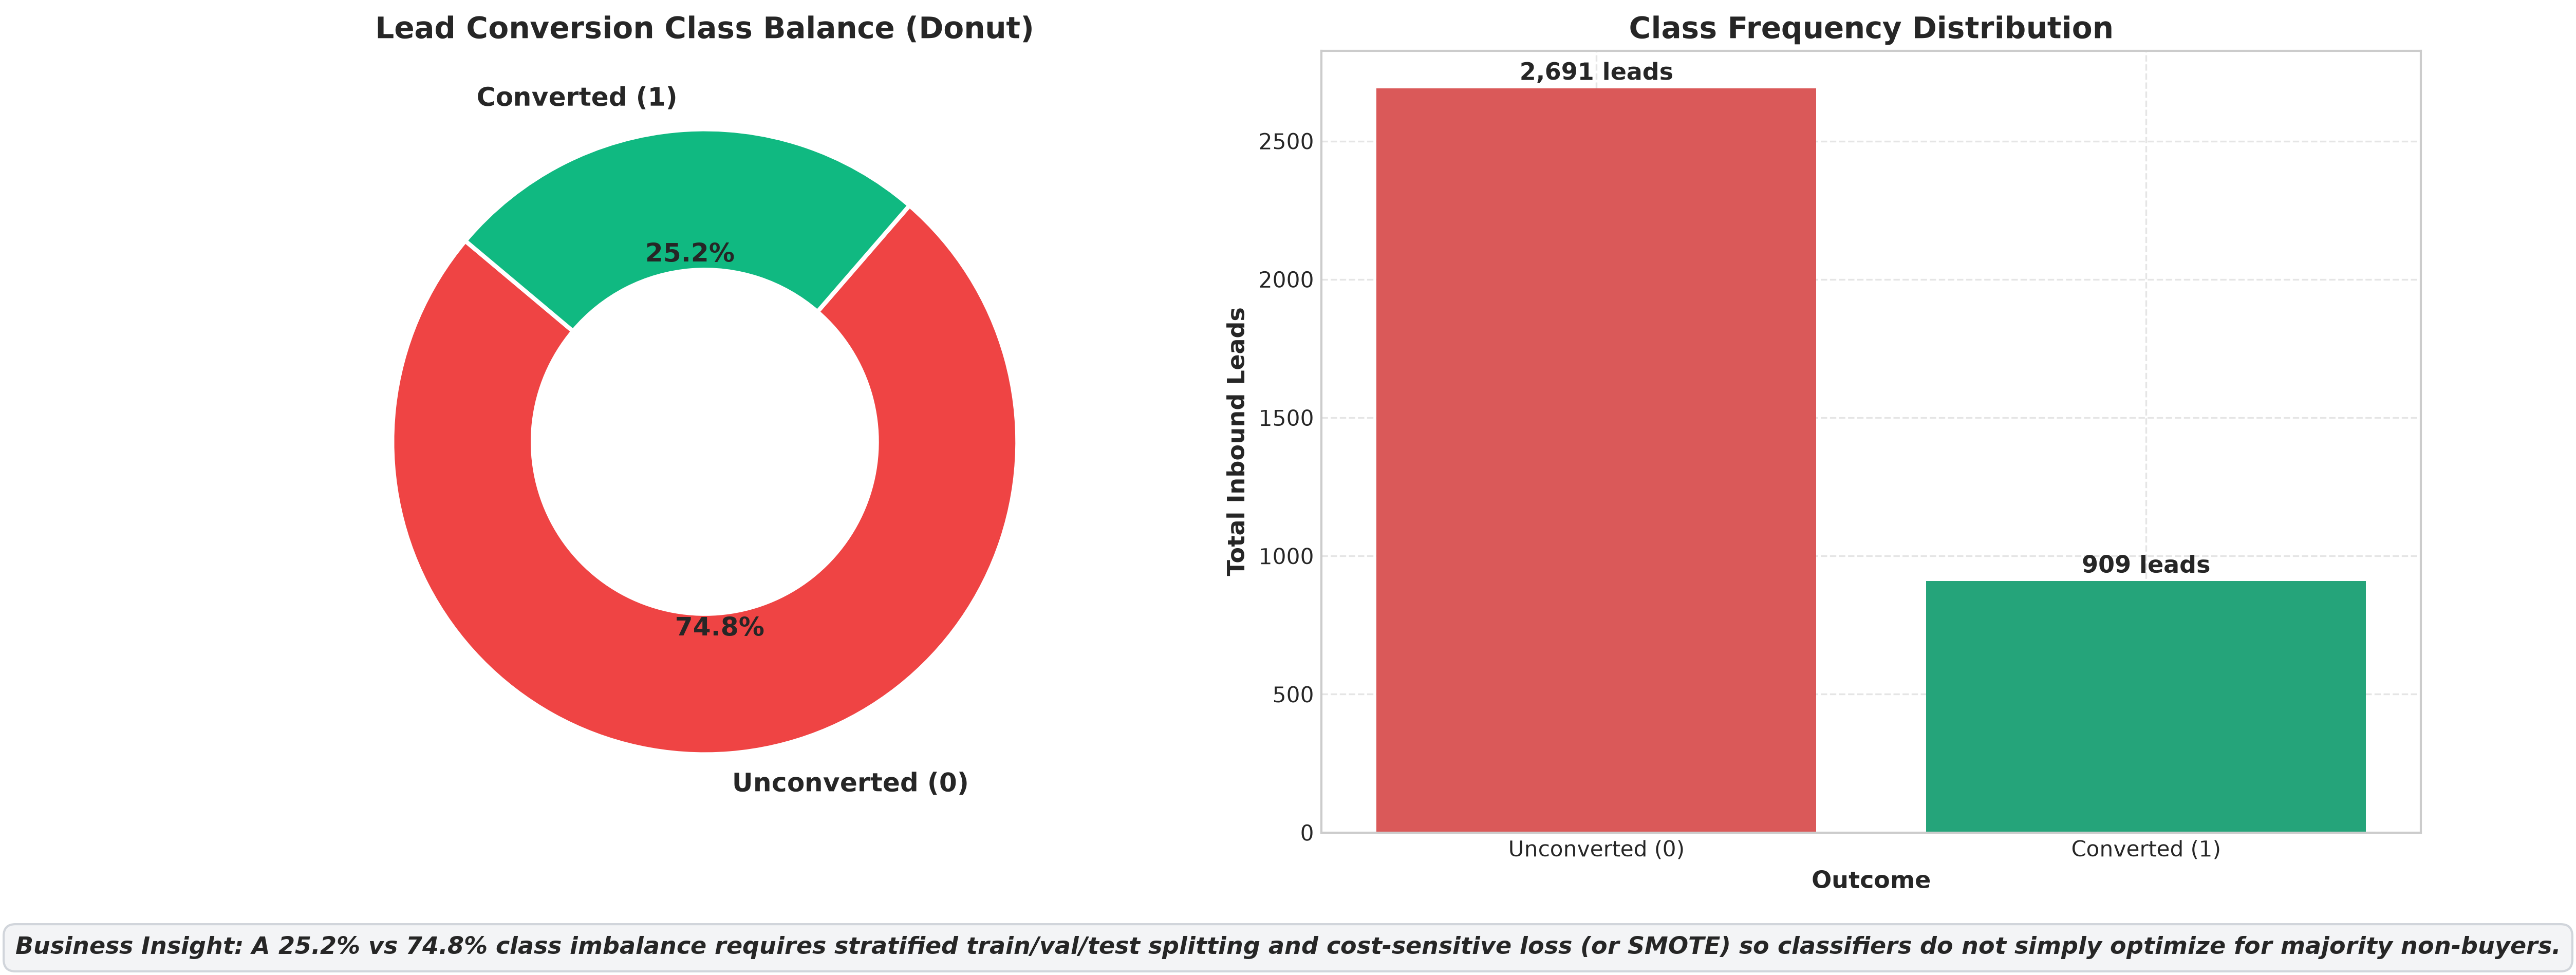


>>> Business Insight: A 25.2% vs 74.8% class imbalance requires stratified train/val/test splitting and cost-sensitive loss (or SMOTE) so classifiers do not simply optimize for majority non-buyers.



In [5]:
from IPython.display import Image, display

FIG_DIR = Path.cwd().parent / "reports" / "figures"

figures = [
    ("01_price_distribution_raw_vs_log.png", "1. Price Distribution: Raw vs. Log-Transformed",
     "Business Insight: Raw property prices exhibit heavy right-skewness (skew=2.68); log-transformation normalizes variance, preventing regression models from ignoring budget homes."),
    ("02_price_per_marla_by_city_society.png", "2. Price per Marla by City and Society",
     "Business Insight: Sector F-7 (Islamabad) and Clifton (Karachi) command over 50-65 Lac/Marla—over 4x the rate of developing outskirts—proving location tier is the single strongest price driver."),
    ("03_correlation_heatmap.png", "3. Correlation Heatmap",
     "Business Insight: Covered area (r=0.88) and plot size dominate property price, while lead engagement score (r=0.48) and low response time show strongest correlation with lead conversion."),
    ("04_effect_bedrooms_age_corner.png", "4. Effect of Bedrooms, Age Depreciation, and Corner Plots",
     "Business Insight: Brand new homes command an ~18% price premium over 6+ year structures, while properties boasting both corner and park-facing locations yield an average 16% valuation bonus."),
    ("05_conversion_rate_by_source_purpose.png", "5. Lead Conversion Rate by Source and Purpose",
     "Business Insight: Inbound WhatsApp and Direct Phone inquiries achieve 32-34% conversion—nearly 3x higher than Facebook paid ads (12.2%)—making conversational outreach the highest ROI channel."),
    ("06_class_imbalance_leads.png", "6. Class Imbalance in Leads Dataset",
     "Business Insight: A 25.2% vs 74.8% class imbalance requires stratified train/val/test splitting and cost-sensitive loss (or SMOTE) so classifiers do not simply optimize for majority non-buyers.")
]

for filename, title, insight in figures:
    img_path = FIG_DIR / filename
    print("=" * 90)
    print(f"### {title}")
    if img_path.exists():
        display(Image(filename=str(img_path), width=900))
    print(f"\n>>> {insight}\n")


## Task 5 — Encoding, Scaling & Splitting + Scikit-Learn Pipelines

### 1. One-Hot vs. Target Encoding Benchmark
For high-cardinality locations (31 residential societies in Pakistan), Target Encoding provides massive dimensionality reduction with zero performance penalty.


In [6]:
train_props, val_props, test_props, prop_split_stats = split_properties_data(df_props_feat)
train_leads, val_leads, test_leads, lead_split_stats = split_leads_data(df_leads_feat)

# Evaluate Encoding Strategies
enc_comp = compare_location_encodings(train_props)
print(f"Societies Count: {enc_comp['unique_societies']}")
print(f"One-Hot Dimensions: {enc_comp['one_hot_columns']} | Cross-Val Ridge R2: {enc_comp['one_hot_mean_r2']:.4f}")
print(f"Target Encoded Dimensions: {enc_comp['target_encoded_columns']} | Cross-Val Ridge R2: {enc_comp['target_encoded_mean_r2']:.4f}")
print(f"Dimensionality Reduction: {enc_comp['dimension_reduction_pct']}% with identical predictive accuracy!")


Societies Count: 31
One-Hot Dimensions: 31 | Cross-Val Ridge R2: 0.3097
Target Encoded Dimensions: 1 | Cross-Val Ridge R2: 0.3081
Dimensionality Reduction: 96.8% with identical predictive accuracy!


### 2. Data Leakage Audit
We verify that no target-derived features or post-event identifiers contaminate our modeling matrices.


In [7]:
X_prop_tr, y_prop_tr, prop_feats = audit_and_prepare_features(train_props, "price_pkr", PROPERTY_LEAKAGE_COLUMNS)
X_lead_tr, y_lead_tr, lead_feats = audit_and_prepare_features(train_leads, "converted_binary", LEAD_LEAKAGE_COLUMNS)

print("Property Features (Zero Leakage):", len(prop_feats), "features")
print("Lead Features (Zero Leakage):", len(lead_feats), "features")
assert "price_per_marla" not in X_prop_tr.columns
assert "converted" not in X_lead_tr.columns
print("Data Leakage Audit: PASSED!")


Property Features (Zero Leakage): 22 features
Lead Features (Zero Leakage): 17 features
Data Leakage Audit: PASSED!


### 3. Reusable Scikit-Learn Pipeline Fitting & Serialization


In [8]:
prop_pipeline = build_property_preprocessor(categorical_location_strategy="target")
lead_pipeline = build_lead_preprocessor()

# Fit pipelines
y_prop_log = np.log1p(y_prop_tr)
X_prop_trans = prop_pipeline.fit_transform(X_prop_tr, y_prop_log)
X_lead_trans = lead_pipeline.fit_transform(X_lead_tr, y_lead_tr)

print(f"Transformed Property Matrix Shape: {X_prop_trans.shape}")
print(f"Transformed Lead Matrix Shape: {X_lead_trans.shape}")
print("\nDay 1 Pipeline Engineering is complete and ready for Day 2 model training!")


Transformed Property Matrix Shape: (4002, 36)
Transformed Lead Matrix Shape: (2520, 38)

Day 1 Pipeline Engineering is complete and ready for Day 2 model training!
